# Language Identification Using LSTM in Google Colab

This notebook walks through importing libraries, uploading a language dataset, tokenizing, training an LSTM model, evaluating metrics, and testing with unseen text.

## Step 1 — Import libraries

In [10]:
import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Step 2 — Load Dataset

Upload a CSV file containing your language data (e.g. `Text` and `Language` columns).

In [11]:

from google.colab import files
uploaded = files.upload()

# Find the uploaded CSV
csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
if not csv_files:
    raise ValueError("Please upload a CSV dataset.")

df = pd.read_csv(csv_files[0])
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Saving dataset.csv to dataset (1).csv
Dataset shape: (22000, 2)
Columns: ['Text', 'language']


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch


## Step 3 — Clean and preprocess the data

In [12]:
# Identify text and language columns
text_col = next((c for c in df.columns if c.lower() in ["text", "sentence", "content"]), None)
label_col = next((c for c in df.columns if c.lower() in ["language", "lang", "label"]), None)

if text_col is None or label_col is None:
    raise ValueError("Could not automatically identify columns. Please verify df.columns and map text_col and label_col manually.")

df = df[[text_col, label_col]].copy()
df.columns = ["text", "language"]

# Handle missing values and duplicates
df.dropna(subset=["text", "language"], inplace=True)
df["text"] = df["text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()
df = df[(df["text"] != "") & (df["language"] != "")]
df.drop_duplicates(inplace=True)

# Basic text preprocessing
def clean_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["text"] = df["text"].apply(clean_text)

# Limit samples per language to balanced distribution
df = df.groupby("language", group_keys=False).apply(
    lambda group: group.sample(n=min(len(group), 1000), random_state=42)
).reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("\nSamples per language:")
print(df["language"].value_counts())

Cleaned dataset shape: (21858, 2)

Samples per language:
language
Chinese       1000
English       1000
Romanian      1000
Persian       1000
Japanese      1000
Korean        1000
Thai          1000
Turkish       1000
Urdu          1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64


/tmp/ipykernel_750/161430180.py:27: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby("language", group_keys=False).apply(


## Step 4 — Tokenization and padding

In [13]:
encoder = LabelEncoder()
y = encoder.fit_transform(df["language"])
X = df["text"].values

# Split train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

MAX_WORDS = 20000
MAX_LEN = 100

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post")
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding="post", truncating="post")

print("Training data shape:", X_train_pad.shape)
print("Testing data shape:", X_test_pad.shape)
print("Number of classes:", len(encoder.classes_))

Training data shape: (17486, 100)
Testing data shape: (4372, 100)
Number of classes: 22


## Step 5 — Build the LSTM model

In [14]:
model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=64, mask_zero=True),
    LSTM(64),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(len(encoder.classes_), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## Step 6 — Train the model

In [20]:
history = model.fit(
    X_train_pad,
    y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/50
246/246 ━━━━━━━━━━━━━━━━━━━━ 14s 59ms/step - accuracy: 0.9225 - loss: 0.2128 - val_accuracy: 0.8754 - val_loss: 0.5365
Epoch 2/50
246/246 ━━━━━━━━━━━━━━━━━━━━ 20s 57ms/step - accuracy: 0.8746 - loss: 0.3696 - val_accuracy: 0.9240 - val_loss: 0.2518
Epoch 3/50
246/246 ━━━━━━━━━━━━━━━━━━━━ 15s 61ms/step - accuracy: 0.9327 - loss: 0.1799 - val_accuracy: 0.9291 - val_loss: 0.2291
Epoch 4/50
246/246 ━━━━━━━━━━━━━━━━━━━━ 20s 59ms/step - accuracy: 0.9426 - loss: 0.1364 - val_accuracy: 0.9302 - val_loss: 0.2250
Epoch 5/50
246/246 ━━━━━━━━━━━━━━━━━━━━ 15s 61ms/step - accuracy: 0.9397 - loss: 0.1481 - val_accuracy: 0.9114 - val_loss: 0.2745
Epoch 6/50
246/246 ━━━━━━━━━━━━━━━━━━━━ 20s 59ms/step - accuracy: 0.9453 - loss: 0.1227 - val_accuracy: 0.9222 - val_loss: 0.2311
Epoch 7/50
246/246 ━━━━━━━━━━━━━━━━━━━━ 15s 61ms/step - accuracy: 0.9474 - loss: 0.1087 - val_accuracy: 0.9228 - val_loss: 0.2371
Epoch 8/50
246/246 ━━━━━━━━━━━━━━━━━━━━ 21s 61ms/step - accuracy: 0.9472 - loss: 0.1055 - 

## Step 7 — Evaluate Accuracy, Precision, Recall, and F1-score

In [21]:
y_prob = model.predict(X_test_pad, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

Accuracy : 0.9321
Precision: 0.9303
Recall   : 0.9321
F1-score : 0.9269

Classification Report:
              precision    recall  f1-score   support

      Arabic       0.99      0.99      0.99       200
     Chinese       0.52      0.80      0.63       200
       Dutch       0.99      0.99      0.99       199
     English       0.91      0.96      0.94       200
    Estonian       0.96      0.96      0.96       200
      French       0.98      0.99      0.98       198
       Hindi       1.00      0.98      0.99       198
  Indonesian       0.99      0.98      0.99       195
    Japanese       0.46      0.18      0.26       200
      Korean       0.99      0.98      0.98       200
       Latin       0.96      0.96      0.96       191
     Persian       1.00      1.00      1.00       200
   Portugese       0.98      0.97      0.98       199
      Pushto       0.98      0.94      0.96       199
    Romanian       0.98      0.98      0.98       200
     Russian       0.97      0.99      

## Step 8 — Confusion Matrix

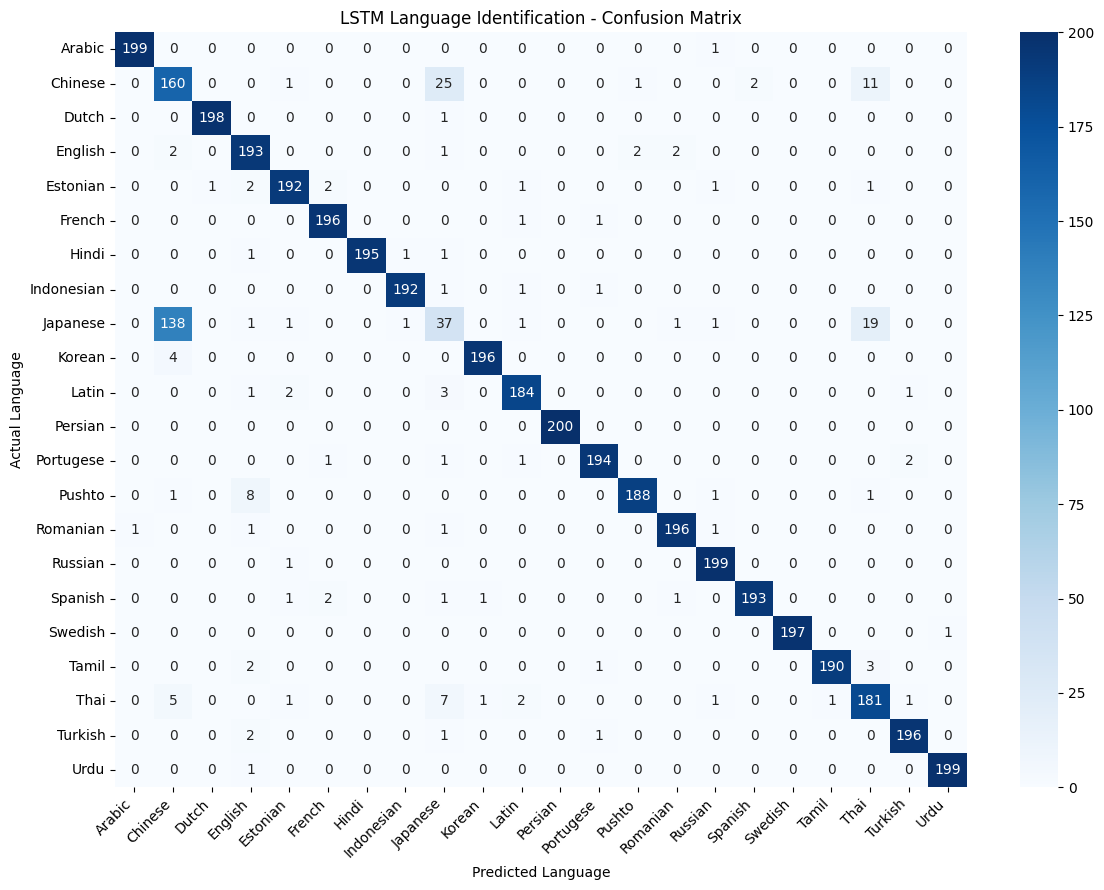

In [22]:
cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(encoder.classes_)))
plt.figure(figsize=(12, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)
plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.title("LSTM Language Identification - Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Step 9 — Plot Training Accuracy

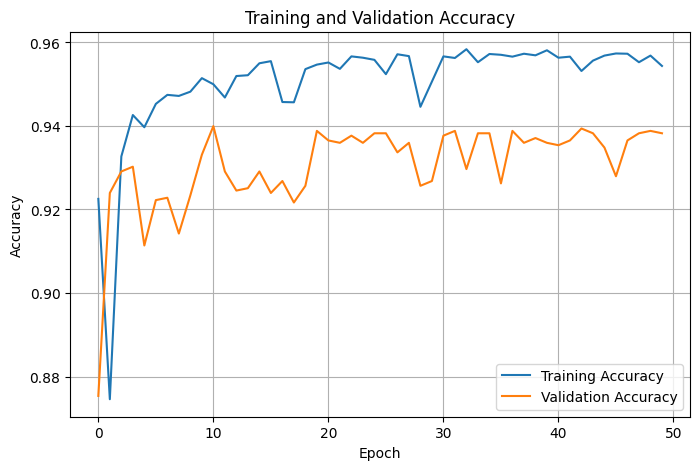

In [23]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

## Step 10 — Predict five unseen text samples

In [25]:
unseen_texts = [
    "Hello, how are you today?",
    "Bonjour, comment allez-vous aujourd'hui ?",
    "Hola, ¿cómo estás hoy?",
    "Guten Morgen, wie geht es dir?",
    "नमस्ते, आप आज कैसे हैं?"
]

unseen_clean = [clean_text(text) for text in unseen_texts]
unseen_sequences = tokenizer.texts_to_sequences(unseen_clean)
unseen_padded = pad_sequences(unseen_sequences, maxlen=MAX_LEN, padding="post", truncating="post")

probabilities = model.predict(unseen_padded, verbose=0)
predicted_labels = np.argmax(probabilities, axis=1)
predicted_languages = encoder.inverse_transform(predicted_labels)

for text, language in zip(unseen_texts, predicted_languages):
    print("Text:", text)
    print("Predicted language:", language)
    print("-" * 40)

Text: Hello, how are you today?
Predicted language: English
----------------------------------------
Text: Bonjour, comment allez-vous aujourd'hui ?
Predicted language: Japanese
----------------------------------------
Text: Hola, ¿cómo estás hoy?
Predicted language: Chinese
----------------------------------------
Text: Guten Morgen, wie geht es dir?
Predicted language: Chinese
----------------------------------------
Text: नमस्ते, आप आज कैसे हैं?
Predicted language: Hindi
----------------------------------------
